# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Nayottama Ivan Rajendra
- **Email:** DS183B6Y1364@student.devacademy.id
- **ID Dicoding:** DS183B6Y1364

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Pada jam berapa puncak penyewaan sepeda terjadi pada hari kerja dibandingkan akhir pekan/hari libur selama periode 2011–2012, dan berapa rata-rata penyewaan per jam pada jam puncak tersebut, sehingga operator dapat menentukan jadwal redistribusi sepeda dan jendela perawatan armada?
- **Pertanyaan 2:** Seberapa besar perbedaan rata-rata penyewaan harian antar musim dan antar kondisi cuaca (cerah, berkabut/mendung, hujan/salju ringan) selama periode 2011–2012, dan berapa persen penurunan permintaan pada kondisi cuaca terburuk dibandingkan cuaca cerah, sehingga tim bisnis dapat menyusun strategi promosi dan penyesuaian armada musiman?

**Pemeriksaan SMART untuk kedua pertanyaan:**

| Elemen | Pertanyaan 1 | Pertanyaan 2 |
|---|---|---|
| **Specific** | Fokus pada *jam puncak* penyewaan, membandingkan hari kerja vs akhir pekan/libur | Fokus pada perbedaan penyewaan harian antar *musim* dan *kondisi cuaca* |
| **Measurable** | Rata-rata penyewaan per jam (`cnt`) dan jam puncaknya | Rata-rata penyewaan harian (`cnt`) dan persentase penurunan terhadap cuaca cerah |
| **Action-Oriented** | Menentukan jadwal redistribusi sepeda, penempatan petugas, dan jam perawatan armada | Menentukan promosi musiman, kesiapan armada, dan perawatan pada musim/cuaca permintaan rendah |
| **Relevant** | Keseimbangan ketersediaan sepeda dan efisiensi operasional adalah masalah inti sistem bike sharing | Permintaan sangat dipengaruhi lingkungan, sehingga pendapatan dan perencanaan armada bergantung pada faktor ini |
| **Time-bound** | Data jam periode 1 Jan 2011 – 31 Des 2012 | Data harian periode 1 Jan 2011 – 31 Des 2012 |

## Import Semua Packages/Library yang Digunakan

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# Gaya visual sederhana (data-ink ratio tinggi): latar putih, tanpa bingkai berlebihan
sns.set_theme(style="white", context="notebook")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 13})

# Palet ramah buta warna (biru = sorotan utama, abu-abu = pembanding, oranye = kategori kedua)
BLUE, LIGHT, ORANGE, GREY = "#1f5aa6", "#a9bfdc", "#e08a1e", "#b5b5b5"

## Data Wrangling

### Gathering Data

#### Load df day (data harian)

In [ ]:
day_df = pd.read_csv("data/day.csv")
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


#### Load df hour (data per jam)

In [ ]:
hour_df = pd.read_csv("data/hour.csv")
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- Dataset **Bike Sharing** (Capital Bikeshare, Washington D.C., 2011–2012) tersedia dalam dua granularitas: `day.csv` (731 baris, 1 baris per hari) dan `hour.csv` (17.379 baris, 1 baris per jam).
- Kedua tabel memiliki kolom yang sama (`season`, `yr`, `mnth`, `holiday`, `weekday`, `workingday`, `weathersit`, `temp`, `atemp`, `hum`, `windspeed`, `casual`, `registered`, `cnt`), hanya `hour.csv` yang memiliki kolom tambahan `hr` (jam 0–23).
- Pertanyaan 1 membutuhkan data per jam (`hour_df`), sedangkan Pertanyaan 2 paling tepat memakai data harian (`day_df`) karena kondisi cuaca dan musim dinyatakan per hari.

### Assessing Data

#### Identifying data type problem

In [ ]:
day_df.info()
print("-" * 60)
hour_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB
------------------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 17379 en

#### Identifying missing value & duplicate data problem

In [ ]:
print("Missing value day_df :", day_df.isna().sum().sum())
print("Missing value hour_df:", hour_df.isna().sum().sum())
print("Duplikasi day_df     :", day_df.duplicated().sum())
print("Duplikasi hour_df    :", hour_df.duplicated().sum())

Missing value day_df : 0
Missing value hour_df: 0
Duplikasi day_df     : 0
Duplikasi hour_df    : 0


#### Identifying invalid value problem

In [ ]:
day_df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [ ]:
hour_df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


In [ ]:
# Kelembapan (hum) = 0 secara fisik tidak masuk akal untuk kota Washington D.C.
print("Jumlah hum = 0 (day_df) :", (day_df["hum"] == 0).sum())
print("Jumlah hum = 0 (hour_df):", (hour_df["hum"] == 0).sum())
print("Tanggal terkait         :", hour_df.loc[hour_df["hum"] == 0, "dteday"].unique())

# Konsistensi cnt = casual + registered
print("\nBaris cnt != casual + registered (day) :", (day_df["cnt"] != day_df["casual"] + day_df["registered"]).sum())
print("Baris cnt != casual + registered (hour):", (hour_df["cnt"] != hour_df["casual"] + hour_df["registered"]).sum())

Jumlah hum = 0 (day_df) : 1
Jumlah hum = 0 (hour_df): 22
Tanggal terkait         : <ArrowStringArray>
['2011-03-10']
Length: 1, dtype: str

Baris cnt != casual + registered (day) : 0
Baris cnt != casual + registered (hour): 0


#### Identifying inconsistent value problem

In [ ]:
# Dokumentasi dataset menyebut season 1 = "springer", namun musim 1 ternyata mencakup Januari-Maret.
pd.crosstab(day_df["mnth"], day_df["season"])

season,1,2,3,4
mnth,,,,
1,62,0,0,0
2,57,0,0,0
3,40,22,0,0
4,0,60,0,0
5,0,62,0,0
6,0,40,20,0
7,0,0,62,0
8,0,0,62,0
9,0,0,44,16


In [ ]:
# Nilai suhu, kelembapan, dan kecepatan angin berupa nilai ternormalisasi (0-1), bukan satuan sebenarnya
day_df[["temp", "atemp", "hum", "windspeed"]].describe().loc[["min", "max"]]

,temp,atemp,hum,windspeed
min,0.059130,0.079070,0.0000,0.022392
max,0.861667,0.840896,0.9725,0.507463


#### Identifying missing records (celah waktu) pada hour_df

In [ ]:
expected = pd.date_range("2011-01-01 00:00", "2012-12-31 23:00", freq="h")
actual = pd.to_datetime(hour_df["dteday"]) + pd.to_timedelta(hour_df["hr"], unit="h")
missing_hours = expected.difference(actual)

print("Jumlah jam yang seharusnya :", len(expected))
print("Jumlah jam yang tercatat   :", len(actual))
print("Jam yang tidak tercatat    :", len(missing_hours))
print("Contoh jam hilang          :", list(missing_hours[:5].strftime("%Y-%m-%d %H:%M")))

Jumlah jam yang seharusnya : 17544
Jumlah jam yang tercatat   : 17379
Jam yang tidak tercatat    : 165
Contoh jam hilang          : ['2011-01-02 05:00', '2011-01-03 02:00', '2011-01-03 03:00', '2011-01-04 03:00', '2011-01-05 03:00']


#### Identifying outlier problem

cnt         outlier day_df:    0 | outlier hour_df:  505 (2.9%)
casual      outlier day_df:   44 | outlier hour_df: 1192 (6.9%)
registered  outlier day_df:    0 | outlier hour_df:  680 (3.9%)


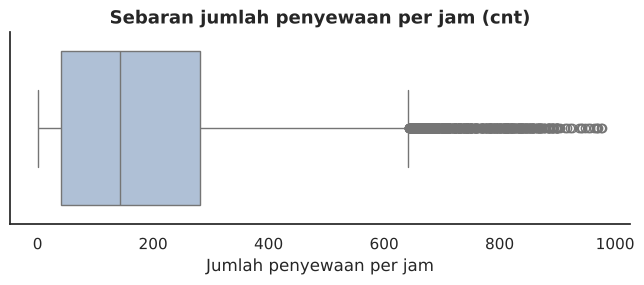

In [ ]:
def count_outliers_iqr(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)).sum()

for col in ["cnt", "casual", "registered"]:
    print(f"{col:<11} outlier day_df: {count_outliers_iqr(day_df[col]):>4} | outlier hour_df: {count_outliers_iqr(hour_df[col]):>4} "
          f"({count_outliers_iqr(hour_df[col]) / len(hour_df):.1%})")

fig, ax = plt.subplots(figsize=(8, 2.5))
sns.boxplot(x=hour_df["cnt"], color=LIGHT, ax=ax)
ax.set_title("Sebaran jumlah penyewaan per jam (cnt)")
ax.set_xlabel("Jumlah penyewaan per jam")
plt.show()

**Steps to Take:**
- **Data type:** kolom `dteday` bertipe teks (`object`/`string`) → ubah ke `datetime`.
- **Invalid value:** `hum = 0` hanya terjadi pada satu hari (2011-03-10; 1 baris di `day_df` dan 22 baris di `hour_df`) → anggap sebagai data tidak valid, ganti dengan **median kelembapan bulan yang sama** (imputasi).
- **Inconsistent value:** kode `season`, `yr`, `mnth`, `weekday`, dan `weathersit` berupa angka dan label musim pada dokumentasi tidak sesuai bulan → buat kolom label yang jelas (musim ditentukan dari bulan: Winter, Spring, Summer, Fall).
- **Inaccurate representation:** `temp`, `atemp`, `hum`, `windspeed` masih ternormalisasi → kembalikan ke satuan asli (°C, %, km/jam) dengan rumus pada Readme (×41, ×50, ×100, ×67).
- **Missing records:** 165 jam tidak tercatat pada `hour_df` (kemungkinan tidak ada transaksi atau sistem tidak mencatat) → **tidak diimputasi** karena tidak ada data pengganti yang valid; dampaknya dicatat pada analisis (rata-rata per jam dihitung dari jam yang tercatat).
- **Outlier:** nilai `cnt` ekstrem merupakan lonjakan permintaan nyata pada jam sibuk, bukan kesalahan input → **dipertahankan**.
- **Fitur turunan:** tambahkan `day_type` (Hari Kerja vs Akhir Pekan/Libur) untuk mendukung analisis.

**Insight:**
- Tidak ada *missing value* maupun data duplikat pada kedua tabel, dan `cnt = casual + registered` konsisten di seluruh baris.
- Masalah kualitas yang ditemukan: tipe data `dteday`, nilai `hum = 0` tidak valid, label kategori tidak informatif/tidak konsisten, nilai lingkungan masih ternormalisasi, dan 165 jam tidak tercatat pada data per jam.
- Sekitar 2,9% baris per jam terdeteksi sebagai outlier menurut IQR, tetapi pola tersebut wajar karena permintaan memang melonjak pada jam sibuk.

### Cleaning Data

#### Fixing data type problem

In [ ]:
for df in (day_df, hour_df):
    df["dteday"] = pd.to_datetime(df["dteday"])

print(day_df["dteday"].dtype, "|", hour_df["dteday"].dtype)

datetime64[us] | datetime64[us]


#### Fixing invalid value problem (hum = 0)

In [ ]:
for df in (day_df, hour_df):
    df["hum"] = df["hum"].replace(0, np.nan)
    # Imputasi dengan median kelembapan pada tahun-bulan yang sama
    df["hum"] = df.groupby(["yr", "mnth"])["hum"].transform(lambda s: s.fillna(s.median()))

print("Sisa hum = 0 / NaN (day_df) :", ((day_df["hum"] == 0) | day_df["hum"].isna()).sum())
print("Sisa hum = 0 / NaN (hour_df):", ((hour_df["hum"] == 0) | hour_df["hum"].isna()).sum())
print("hum pada 2011-03-10 (day_df):", round(day_df.loc[day_df["dteday"] == "2011-03-10", "hum"].iloc[0], 3))

Sisa hum = 0 / NaN (day_df) : 0
Sisa hum = 0 / NaN (hour_df): 0
hum pada 2011-03-10 (day_df): 0.573


#### Fixing inconsistent value problem (label kategori)

In [ ]:
season_map = {1: "Winter", 2: "Spring", 3: "Summer", 4: "Fall"}   # berdasarkan bulan pada crosstab di atas
weather_map = {1: "Cerah/Berawan Sebagian", 2: "Berkabut/Mendung",
               3: "Hujan/Salju Ringan", 4: "Hujan Lebat/Salju"}
weekday_map = {0: "Minggu", 1: "Senin", 2: "Selasa", 3: "Rabu", 4: "Kamis", 5: "Jumat", 6: "Sabtu"}
month_map = {1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "Mei", 6: "Jun",
             7: "Jul", 8: "Agu", 9: "Sep", 10: "Okt", 11: "Nov", 12: "Des"}

for df in (day_df, hour_df):
    df["season_name"] = df["season"].map(season_map)
    df["weather_label"] = df["weathersit"].map(weather_map)
    df["weekday_name"] = df["weekday"].map(weekday_map)
    df["month_name"] = df["mnth"].map(month_map)
    df["year"] = df["yr"].map({0: 2011, 1: 2012})
    df["day_type"] = np.where(df["workingday"] == 1, "Hari Kerja", "Akhir Pekan/Libur")

day_df[["dteday", "season_name", "weather_label", "weekday_name", "year", "day_type"]].sample(5, random_state=1)

,dteday,season_name,weather_label,weekday_name,year,day_type
404,2012-02-09,Winter,Cerah/Berawan Sebagian,Kamis,2012,Hari Kerja
726,2012-12-27,Winter,Berkabut/Mendung,Kamis,2012,Hari Kerja
159,2011-06-09,Spring,Berkabut/Mendung,Kamis,2011,Hari Kerja
422,2012-02-27,Winter,Cerah/Berawan Sebagian,Senin,2012,Hari Kerja
512,2012-05-27,Spring,Cerah/Berawan Sebagian,Minggu,2012,Akhir Pekan/Libur


#### Fixing inaccurate representation (denormalisasi satuan)

In [ ]:
for df in (day_df, hour_df):
    df["temp_c"] = df["temp"] * 41            # suhu (°C)
    df["atemp_c"] = df["atemp"] * 50          # suhu terasa (°C)
    df["hum_pct"] = df["hum"] * 100           # kelembapan (%)
    df["windspeed_kmh"] = df["windspeed"] * 67  # kecepatan angin (km/jam)

day_df[["temp_c", "atemp_c", "hum_pct", "windspeed_kmh"]].describe().round(1)

,temp_c,atemp_c,hum_pct,windspeed_kmh
count,731.0,731.0,731.0,731.0
mean,20.3,23.7,62.9,12.8
std,7.5,8.1,14.1,5.2
min,2.4,4.0,18.8,1.5
25%,13.8,16.9,52.1,9.0
50%,20.4,24.3,62.7,12.1
75%,26.9,30.4,73.0,15.6
max,35.3,42.0,97.2,34.0


#### Menangani outlier & menyimpan data bersih

In [ ]:
# Outlier cnt dipertahankan karena merupakan lonjakan permintaan nyata pada jam sibuk.
# Data bersih disimpan sebagai sumber data dashboard.
import os
os.makedirs("dashboard", exist_ok=True)

hour_df.to_csv("dashboard/main_data.csv", index=False)
day_df.to_csv("dashboard/day_data.csv", index=False)

print("Ukuran day_df :", day_df.shape)
print("Ukuran hour_df:", hour_df.shape)
hour_df.head()

Ukuran day_df : (731, 26)
Ukuran hour_df: (17379, 27)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,...,season_name,weather_label,weekday_name,month_name,year,day_type,temp_c,atemp_c,hum_pct,windspeed_kmh
0,1,2011-01-01,1,0,1,0,0,6,0,1,...,Winter,Cerah/Berawan Sebagian,Sabtu,Jan,2011,Akhir Pekan/Libur,9.84,14.395,81.0,0.0
1,2,2011-01-01,1,0,1,1,0,6,0,1,...,Winter,Cerah/Berawan Sebagian,Sabtu,Jan,2011,Akhir Pekan/Libur,9.02,13.635,80.0,0.0
2,3,2011-01-01,1,0,1,2,0,6,0,1,...,Winter,Cerah/Berawan Sebagian,Sabtu,Jan,2011,Akhir Pekan/Libur,9.02,13.635,80.0,0.0
3,4,2011-01-01,1,0,1,3,0,6,0,1,...,Winter,Cerah/Berawan Sebagian,Sabtu,Jan,2011,Akhir Pekan/Libur,9.84,14.395,75.0,0.0
4,5,2011-01-01,1,0,1,4,0,6,0,1,...,Winter,Cerah/Berawan Sebagian,Sabtu,Jan,2011,Akhir Pekan/Libur,9.84,14.395,75.0,0.0


**Insight:**
- Setelah pembersihan, `dteday` bertipe `datetime64`, kelembapan tidak lagi bernilai 0, dan seluruh variabel lingkungan sudah memakai satuan asli sehingga mudah ditafsirkan (mis. suhu dalam °C).
- Penamaan musim dikoreksi berdasarkan bulan sebenarnya: **Winter = Jan–Mar, Spring = Apr–Jun, Summer = Jul–Sep, Fall = Okt–Des**, sehingga analisis musiman tidak menyesatkan.
- Data bersih disimpan ke `dashboard/main_data.csv` (per jam) dan `dashboard/day_data.csv` (harian) agar dashboard memakai data yang sama dengan notebook.

## Exploratory Data Analysis (EDA)

### Explore day_df: ringkasan, pertumbuhan tahunan, dan komposisi pengguna

In [ ]:
day_df.describe(include="all").T.round(2)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
instant,731.0,NaN,NaN,NaN,366.0,1.0,183.5,366.0,548.5,731.0,211.165812
dteday,731,NaN,NaN,NaN,2012-01-01 00:00:00,2011-01-01 00:00:00,2011-07-02 12:00:00,2012-01-01 00:00:00,2012-07-01 12:00:00,2012-12-31 00:00:00,NaN
season,731.0,NaN,NaN,NaN,2.49658,1.0,2.0,3.0,3.0,4.0,1.110807
yr,731.0,NaN,NaN,NaN,0.500684,0.0,0.0,1.0,1.0,1.0,0.500342
mnth,731.0,NaN,NaN,NaN,6.519836,1.0,4.0,7.0,10.0,12.0,3.451913
holiday,731.0,NaN,NaN,NaN,0.028728,0.0,0.0,0.0,0.0,1.0,0.167155
weekday,731.0,NaN,NaN,NaN,2.997264,0.0,1.0,3.0,5.0,6.0,2.004787
workingday,731.0,NaN,NaN,NaN,0.683995,0.0,0.0,1.0,1.0,1.0,0.465233
weathersit,731.0,NaN,NaN,NaN,1.395349,1.0,1.0,1.0,2.0,3.0,0.544894
temp,731.0,NaN,NaN,NaN,0.495385,0.05913,0.337083,0.498333,0.655417,0.861667,0.183051


In [ ]:
# Pertumbuhan penyewaan 2011 -> 2012 dan komposisi pengguna
yearly = day_df.groupby("year").agg(
    total_cnt=("cnt", "sum"),
    avg_daily_cnt=("cnt", "mean"),
    casual=("casual", "sum"),
    registered=("registered", "sum"),
).round(0)
yearly["registered_share"] = (yearly["registered"] / yearly["total_cnt"]).round(3)
print(yearly)
print("\nPertumbuhan rata-rata harian 2012 vs 2011: {:.1%}".format(
    yearly.loc[2012, "avg_daily_cnt"] / yearly.loc[2011, "avg_daily_cnt"] - 1))

      total_cnt  avg_daily_cnt  casual  registered  registered_share
year                                                                
2011    1243103         3406.0  247252      995851             0.801
2012    2049576         5600.0  372765     1676811             0.818

Pertumbuhan rata-rata harian 2012 vs 2011: 64.4%


### Explore day_df: musim dan kondisi cuaca (bahan Pertanyaan 2)

In [ ]:
season_order = ["Winter", "Spring", "Summer", "Fall"]
weather_order = ["Cerah/Berawan Sebagian", "Berkabut/Mendung", "Hujan/Salju Ringan"]

by_season = day_df.groupby("season_name").agg(jumlah_hari=("cnt", "size"), rata2_cnt=("cnt", "mean"),
                                              rata2_suhu_c=("temp_c", "mean")).reindex(season_order).round(1)
by_weather = day_df.groupby("weather_label").agg(jumlah_hari=("cnt", "size"), rata2_cnt=("cnt", "mean")
                                                 ).reindex(weather_order).round(1)
by_weather["selisih_vs_cerah"] = (by_weather["rata2_cnt"] / by_weather.loc["Cerah/Berawan Sebagian", "rata2_cnt"] - 1).map("{:.1%}".format)
print(by_season, "\n")
print(by_weather)

             jumlah_hari  rata2_cnt  rata2_suhu_c
season_name                                      
Winter               181     2604.1          12.2
Spring               184     4992.3          22.3
Summer               188     5644.3          29.0
Fall                 178     4728.2          17.3 

                        jumlah_hari  rata2_cnt selisih_vs_cerah
weather_label                                                  
Cerah/Berawan Sebagian          463     4876.8             0.0%
Berkabut/Mendung                247     4035.9           -17.2%
Hujan/Salju Ringan               21     1803.3           -63.0%


In [ ]:
# Korelasi variabel lingkungan dengan jumlah penyewaan harian
day_df[["temp_c", "hum_pct", "windspeed_kmh", "cnt"]].corr()["cnt"].drop("cnt").round(2)

temp_c           0.63
hum_pct         -0.11
windspeed_kmh   -0.23
Name: cnt, dtype: float64

In [ ]:
# Kombinasi musim x cuaca (rata-rata penyewaan harian)
day_df.pivot_table(index="season_name", columns="weather_label", values="cnt", aggfunc="mean").reindex(season_order)[weather_order].round(0)

weather_label,Cerah/Berawan Sebagian,Berkabut/Mendung,Hujan/Salju Ringan
season_name,,,
Winter,2811.0,2357.0,935.0
Spring,5549.0,4237.0,1169.0
Summer,5878.0,5222.0,2752.0
Fall,5044.0,4654.0,1962.0


### Explore hour_df: pola penyewaan per jam (bahan Pertanyaan 1)

In [ ]:
hourly_pivot = hour_df.pivot_table(index="hr", columns="day_type", values="cnt", aggfunc="mean").round(1)
print(hourly_pivot)
print("\nJam puncak per tipe hari:")
print(hourly_pivot.idxmax().to_frame("jam_puncak").join(hourly_pivot.max().rename("rata2_cnt_puncak")))

day_type  Akhir Pekan/Libur  Hari Kerja
hr                                     
0                      90.8        36.8
1                      69.5        16.6
2                      53.2         8.7
3                      25.8         4.9
4                       8.3         5.4
5                       8.7        24.9
6                      18.7       102.5
7                      43.4       290.6
8                     105.7       477.0
9                     171.6       241.5
10                    255.9       135.4
11                    315.3       158.2
12                    366.3       200.8
13                    372.7       198.4
14                    364.6       183.6
15                    358.8       201.3
16                    352.7       293.1
17                    323.5       525.3
18                    281.1       492.2
19                    231.7       348.4
20                    174.7       249.7
21                    142.1       186.3
22                    116.1       138.4


In [ ]:
# Jumlah hari per tipe hari dan kontribusi jam sibuk terhadap total penyewaan
print(hour_df.groupby("day_type")["dteday"].nunique().to_frame("jumlah_hari"))

rush = [7, 8, 17, 18]
share = hour_df.assign(rush=hour_df["hr"].isin(rush)).groupby("day_type").apply(
    lambda g: g.loc[g["rush"], "cnt"].sum() / g["cnt"].sum(), include_groups=False)
print("\nKontribusi jam 07-08 & 17-18 terhadap total penyewaan:")
print(share.map("{:.1%}".format))

                   jumlah_hari
day_type                      
Akhir Pekan/Libur          231
Hari Kerja                 500

Kontribusi jam 07-08 & 17-18 terhadap total penyewaan:
day_type
Akhir Pekan/Libur    17.4%
Hari Kerja           38.7%
dtype: str


In [ ]:
# Rata-rata penyewaan harian menurut hari dalam seminggu
weekday_order = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]
day_df.groupby("weekday_name")["cnt"].mean().reindex(weekday_order).round(0)

weekday_name
Senin     4338.0
Selasa    4511.0
Rabu      4549.0
Kamis     4667.0
Jumat     4690.0
Sabtu     4551.0
Minggu    4229.0
Name: cnt, dtype: float64

**Insight:**
- **Pertumbuhan:** rata-rata penyewaan harian naik dari ±3.406 (2011) menjadi ±5.600 (2012), atau **+64,4%**. Pengguna terdaftar (*registered*) mendominasi (80,1% pada 2011 dan 81,8% pada 2012).
- **Musim:** rata-rata penyewaan harian tertinggi pada **Summer (±5.644)** dan terendah pada **Winter (±2.604)**. Spring (±4.992) dan Fall (±4.728) berada di tengah.
- **Cuaca:** rata-rata harian pada cuaca cerah ±4.877, berkabut/mendung ±4.036 (−17,2%), dan hujan/salju ringan hanya ±1.803 (**−63,0%**). Hari dengan cuaca hujan/salju ringan hanya 21 hari sehingga perlu ditafsirkan hati-hati.
- **Korelasi:** suhu berkorelasi positif sedang dengan penyewaan (r ≈ 0,63), sedangkan kecepatan angin (r ≈ −0,23) dan kelembapan (r ≈ −0,11) berkorelasi negatif lemah.
- **Pola jam:** hari kerja memiliki dua puncak (08.00 ±477 dan 17.00 ±525 penyewaan/jam), sedangkan akhir pekan/libur memiliki satu puncak siang hari (13.00 ±373). Empat jam sibuk (07–08 dan 17–18) menyumbang 38,7% penyewaan hari kerja.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Pada jam berapa puncak penyewaan sepeda terjadi pada hari kerja dibandingkan akhir pekan/hari libur, dan berapa rata-rata penyewaannya?

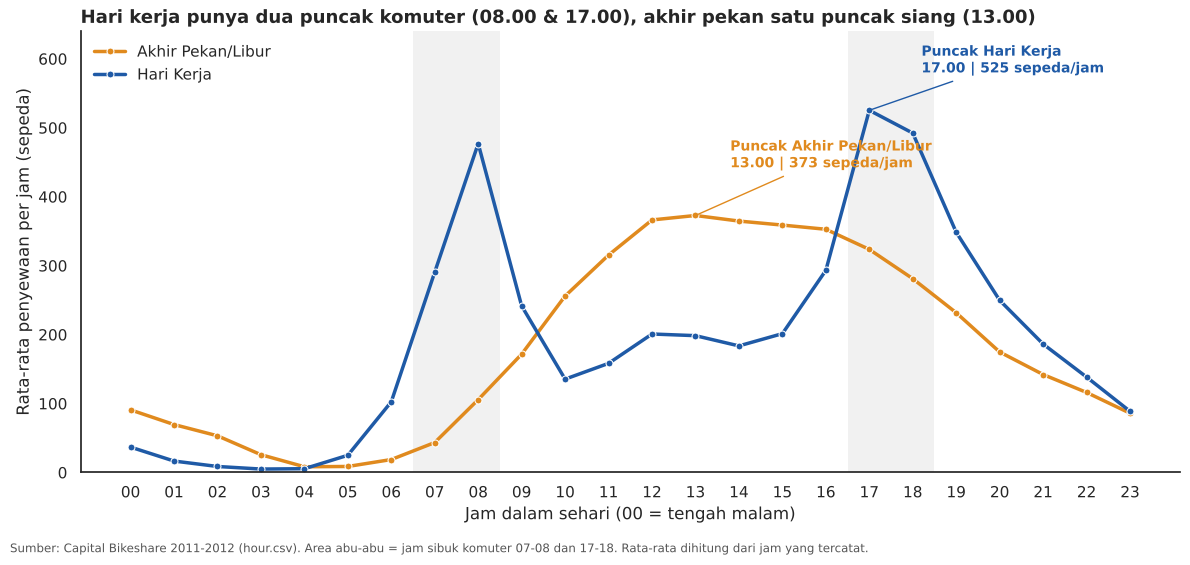

In [ ]:
hourly = hour_df.groupby(["hr", "day_type"])["cnt"].mean().reset_index()
palette = {"Hari Kerja": BLUE, "Akhir Pekan/Libur": ORANGE}

fig, ax = plt.subplots(figsize=(12, 5.5))
sns.lineplot(data=hourly, x="hr", y="cnt", hue="day_type", palette=palette,
             linewidth=2.5, marker="o", markersize=5, ax=ax)

# Beri label langsung pada titik puncak (menggantikan legenda yang berjauhan dari data)
for tipe, color in palette.items():
    sub = hourly[hourly["day_type"] == tipe]
    peak = sub.loc[sub["cnt"].idxmax()]
    ax.annotate(f"Puncak {tipe}\n{int(peak['hr']):02d}.00 | {peak['cnt']:.0f} sepeda/jam",
                xy=(peak["hr"], peak["cnt"]), xytext=(peak["hr"] + (1.2 if tipe == "Hari Kerja" else 0.8), peak["cnt"] + (55 if tipe == "Hari Kerja" else 70)),
                color=color, fontweight="bold", fontsize=10,
                arrowprops=dict(arrowstyle="-", color=color))

# Sorot jam sibuk hari kerja dengan area abu-abu tipis
for a, b in [(6.5, 8.5), (16.5, 18.5)]:
    ax.axvspan(a, b, color=GREY, alpha=0.18, lw=0)

ax.set_ylim(0, 640)                      # sumbu Y dimulai dari nol agar proporsi jujur
ax.set_xticks(range(0, 24))
ax.set_xticklabels([f"{h:02d}" for h in range(24)])
ax.set_xlabel("Jam dalam sehari (00 = tengah malam)")
ax.set_ylabel("Rata-rata penyewaan per jam (sepeda)")
ax.set_title("Hari kerja punya dua puncak komuter (08.00 & 17.00), akhir pekan satu puncak siang (13.00)", loc="left")
ax.legend(title=None, frameon=False, loc="upper left")
sns.despine()
plt.figtext(0.01, -0.02, "Sumber: Capital Bikeshare 2011-2012 (hour.csv). Area abu-abu = jam sibuk komuter 07-08 dan 17-18. "
            "Rata-rata dihitung dari jam yang tercatat.", fontsize=8.5, color="#555555")
plt.tight_layout()
plt.show()

**Insight Pertanyaan 1:**
- Pada **hari kerja**, penyewaan mengikuti pola komuter: puncak pagi pukul **08.00 (±477 sepeda/jam)** dan puncak sore pukul **17.00 (±525 sepeda/jam)** yang merupakan puncak tertinggi harian.
- Pada **akhir pekan/hari libur**, hanya ada satu puncak landai pada pukul **13.00 (±373 sepeda/jam)**, dan permintaan relatif tinggi sepanjang 11.00–16.00.
- Pada dini hari (00.00–05.00) permintaan sangat rendah (rata-rata gabungan di bawah 80 sepeda/jam), sehingga menjadi jendela yang tepat untuk perawatan dan redistribusi armada.

### Pertanyaan 2: Seberapa besar perbedaan rata-rata penyewaan harian antar musim dan kondisi cuaca, dan berapa penurunan pada cuaca terburuk dibanding cuaca cerah?

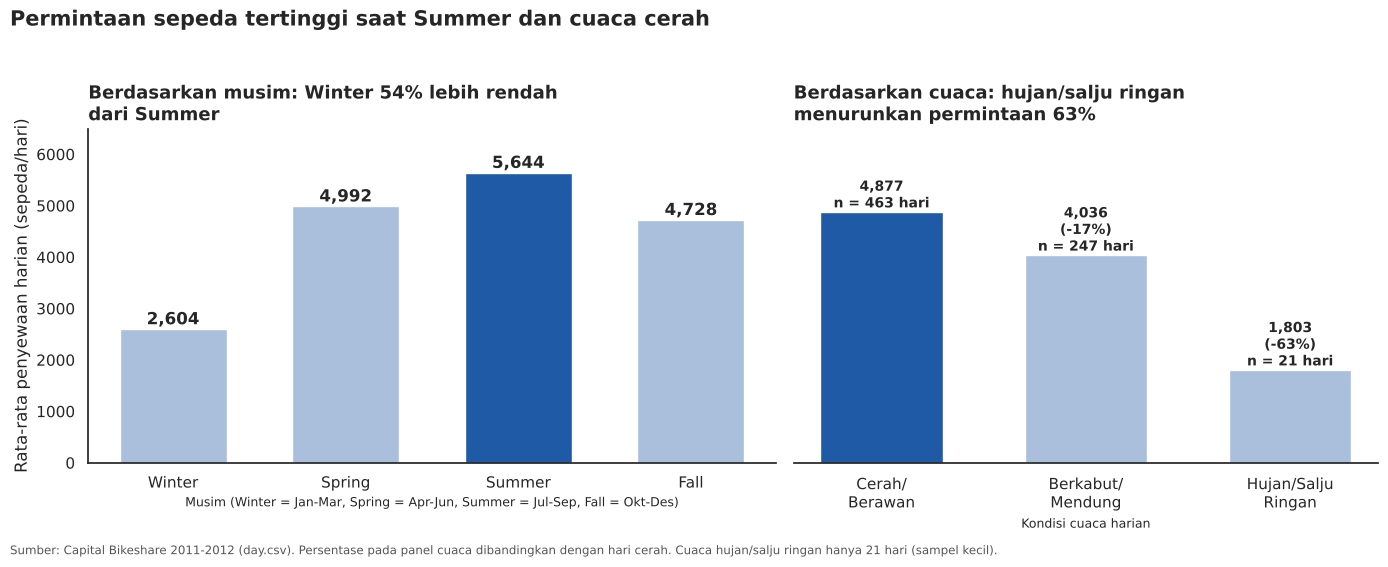

In [ ]:
season_avg = day_df.groupby("season_name")["cnt"].mean().reindex(season_order)
weather_avg = day_df.groupby("weather_label")["cnt"].mean().reindex(weather_order)
weather_n = day_df["weather_label"].value_counts().reindex(weather_order)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [4, 3.4]})

# --- Panel kiri: musim (sorot musim tertinggi) ---
ax = axes[0]
colors = [BLUE if v == season_avg.max() else LIGHT for v in season_avg]
bars = ax.bar(season_avg.index, season_avg.values, color=colors, width=0.62)
for b, v in zip(bars, season_avg.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 90, f"{v:,.0f}", ha="center", fontweight="bold")
ax.set_ylim(0, 6500)
ax.set_ylabel("Rata-rata penyewaan harian (sepeda/hari)")
ax.set_xlabel("Musim (Winter = Jan-Mar, Spring = Apr-Jun, Summer = Jul-Sep, Fall = Okt-Des)", fontsize=9)
ax.set_title("Berdasarkan musim: Winter 54% lebih rendah\ndari Summer", loc="left")

# --- Panel kanan: cuaca (cerah sebagai acuan) ---
ax = axes[1]
colors = [BLUE, LIGHT, LIGHT]
bars = ax.bar(["Cerah/\nBerawan", "Berkabut/\nMendung", "Hujan/Salju\nRingan"], weather_avg.values, color=colors, width=0.6)
base = weather_avg.iloc[0]
for b, v, n in zip(bars, weather_avg.values, weather_n.values):
    pct = "" if v == base else f"\n({v / base - 1:+.0%})"
    ax.text(b.get_x() + b.get_width() / 2, v + 90, f"{v:,.0f}{pct}\nn = {n} hari", ha="center", fontweight="bold", fontsize=10)
ax.set_ylim(0, 6500)
ax.set_ylabel("")
ax.set_yticklabels([])
ax.tick_params(left=False)
ax.spines["left"].set_visible(False)
ax.set_xlabel("Kondisi cuaca harian", fontsize=9)
ax.set_title("Berdasarkan cuaca: hujan/salju ringan\nmenurunkan permintaan 63%", loc="left")

fig.suptitle("Permintaan sepeda tertinggi saat Summer dan cuaca cerah", x=0.01, ha="left", fontsize=15, fontweight="bold")
fig.text(0.01, -0.01, "Sumber: Capital Bikeshare 2011-2012 (day.csv). Persentase pada panel cuaca dibandingkan dengan hari cerah. "
         "Cuaca hujan/salju ringan hanya 21 hari (sampel kecil).", fontsize=8.5, color="#555555")
sns.despine(ax=axes[0]); sns.despine(ax=axes[1], left=True)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

**Insight:**
- **Musim:** Summer menjadi musim tertinggi (±5.644 sepeda/hari), sedangkan Winter terendah (±2.604 sepeda/hari), yaitu **53,9% lebih rendah** dibanding Summer. Spring dan Fall masing-masing 11,6% dan 16,2% di bawah Summer.
- **Cuaca:** dibanding hari cerah (±4.877 sepeda/hari), cuaca berkabut/mendung menurunkan permintaan **17,2%** dan hujan/salju ringan menurunkan hingga **63,0%** (n = 21 hari).
- Cuaca buruk menekan permintaan di semua musim; rata-rata terendah terjadi pada Winter dengan cuaca hujan/salju ringan (±935 sepeda/hari).

## Analisis Lanjutan (Opsional)

**Tujuan analisis lanjutan:** menerapkan teknik **Clustering tanpa algoritma machine learning** berupa *Manual Grouping* dan *Binning*, karena dataset tidak memiliki dimensi lokasi (geospatial) maupun identitas pelanggan (RFM) sehingga kedua teknik tersebut tidak relevan. Tiga analisis dilakukan:
1. **Binning suhu** (Dingin, Sejuk, Hangat, Panas) untuk mengukur titik suhu dengan permintaan terbaik, melengkapi Pertanyaan 2.
2. **Manual grouping jam** ke dalam klaster permintaan *Rendah / Sedang / Tinggi* berdasarkan rata-rata penyewaan per jam, melengkapi Pertanyaan 1.
3. **Heatmap jam × hari** untuk melihat pola kombinasi waktu secara menyeluruh.

                  jumlah_hari  rata2_cnt
temp_group                              
Dingin (<10°C)             60     1678.0
Sejuk (10-20°C)           299     3692.0
Hangat (20-30°C)          300     5662.0
Panas (>30°C)              72     5410.0


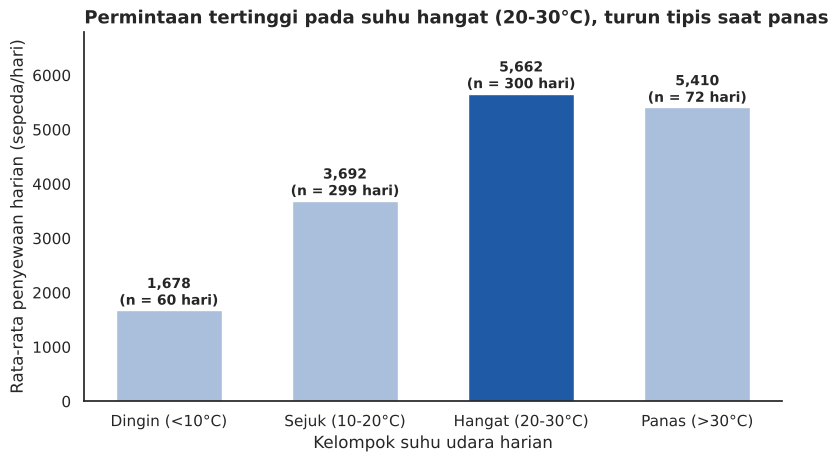

In [ ]:
# 1) Binning suhu (°C) -> kategori
bins = [-np.inf, 10, 20, 30, np.inf]
labels = ["Dingin (<10°C)", "Sejuk (10-20°C)", "Hangat (20-30°C)", "Panas (>30°C)"]
day_df["temp_group"] = pd.cut(day_df["temp_c"], bins=bins, labels=labels)

temp_summary = day_df.groupby("temp_group", observed=True).agg(jumlah_hari=("cnt", "size"), rata2_cnt=("cnt", "mean")).round(0)
print(temp_summary)

fig, ax = plt.subplots(figsize=(9, 4.8))
colors = [BLUE if v == temp_summary["rata2_cnt"].max() else LIGHT for v in temp_summary["rata2_cnt"]]
bars = ax.bar(temp_summary.index.astype(str), temp_summary["rata2_cnt"], color=colors, width=0.6)
for b, v, n in zip(bars, temp_summary["rata2_cnt"], temp_summary["jumlah_hari"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 100, f"{v:,.0f}\n(n = {n} hari)", ha="center", fontsize=10, fontweight="bold")
ax.set_ylim(0, 6800)
ax.set_ylabel("Rata-rata penyewaan harian (sepeda/hari)")
ax.set_xlabel("Kelompok suhu udara harian")
ax.set_title("Permintaan tertinggi pada suhu hangat (20-30°C), turun tipis saat panas", loc="left")
sns.despine()
plt.show()

In [ ]:
# 2) Manual grouping jam ke dalam klaster permintaan
hour_profile = hour_df.groupby("hr")["cnt"].mean().round(1).to_frame("rata2_cnt")
hour_profile["klaster"] = pd.cut(hour_profile["rata2_cnt"], bins=[0, 100, 300, np.inf],
                                 labels=["Rendah (<100)", "Sedang (100-300)", "Tinggi (>300)"])
cluster_summary = hour_profile.reset_index().groupby("klaster", observed=True).agg(
    jam=("hr", lambda s: ", ".join(f"{h:02d}" for h in s)),
    rata2_cnt=("rata2_cnt", "mean")).round(0)
cluster_summary

,jam,rata2_cnt
klaster,,
Rendah (<100),"00, 01, 02, 03, 04, 05, 06, 23",39.0
Sedang (100-300),"07, 09, 10, 11, 12, 13, 14, 15, 20, 21, 22",213.0
Tinggi (>300),"08, 16, 17, 18, 19",374.0


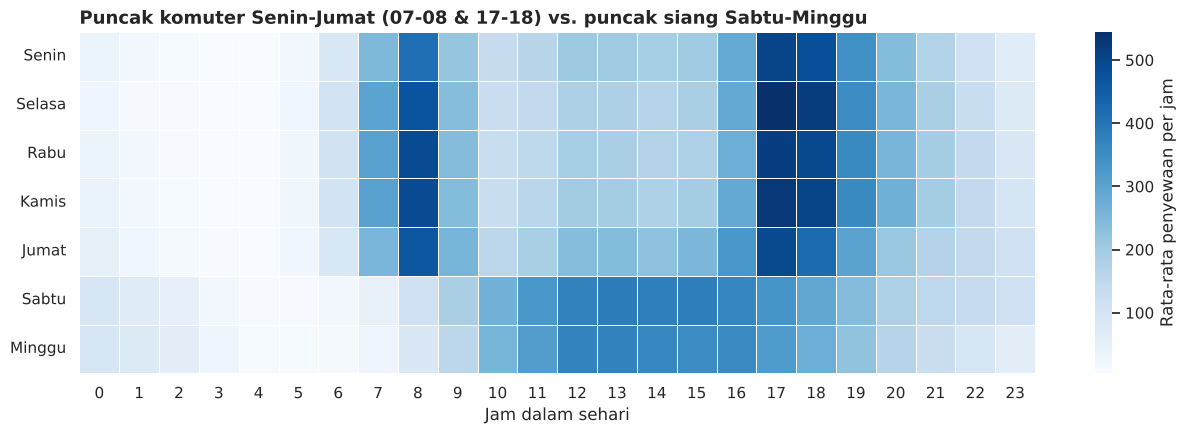

In [ ]:
# 3) Heatmap rata-rata penyewaan: jam x hari dalam seminggu
heat = hour_df.pivot_table(index="weekday_name", columns="hr", values="cnt", aggfunc="mean").reindex(weekday_order)

fig, ax = plt.subplots(figsize=(13, 4.5))
sns.heatmap(heat, cmap="Blues", linewidths=0.4, linecolor="white", cbar_kws={"label": "Rata-rata penyewaan per jam"}, ax=ax)
ax.set_xlabel("Jam dalam sehari")
ax.set_ylabel("")
ax.set_title("Puncak komuter Senin-Jumat (07-08 & 17-18) vs. puncak siang Sabtu-Minggu", loc="left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Insight:**
- **Binning suhu:** permintaan meningkat tajam dari kelompok Dingin (±1.678/hari) ke Sejuk (±3.692) dan Hangat (±5.662), lalu **turun tipis** pada kelompok Panas (±5.410; hanya 72 hari). Rentang **20–30°C** adalah kondisi paling ideal untuk bersepeda.
- **Klaster jam:** klaster *Tinggi* (>300 sepeda/jam rata-rata) berisi jam 08, 16, 17, 18, dan 19; klaster *Rendah* (<100) mencakup 00–06 dan 23; sisanya *Sedang*. Klaster ini dapat langsung dipakai sebagai dasar penjadwalan operasional.
- **Heatmap:** Senin–Jumat menunjukkan dua blok warna pekat (pagi dan sore), sedangkan Sabtu–Minggu menunjukkan satu blok lebar di siang hari. Pola ini mengonfirmasi hasil Pertanyaan 1 secara menyeluruh.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Puncak penyewaan hari kerja terjadi pada pukul **17.00 (±525 sepeda/jam)** dan **08.00 (±477 sepeda/jam)**, mencerminkan pola komuter; keempat jam sibuk (07–08 dan 17–18) menyumbang 38,7% penyewaan hari kerja. Pada akhir pekan/hari libur, puncaknya hanya satu, yaitu pukul **13.00 (±373 sepeda/jam)** dengan permintaan tinggi di rentang 11.00–16.00. Permintaan terendah terjadi pukul 00.00–05.00 (di bawah 80 sepeda/jam).
- **Conclusion pertanyaan 2:** Rata-rata penyewaan harian tertinggi terjadi pada **Summer (±5.644)** dan terendah pada **Winter (±2.604; −53,9%)**. Berdasarkan cuaca, kondisi berkabut/mendung menurunkan permintaan **17,2%** dan hujan/salju ringan menurunkan **63,0%** dibanding cuaca cerah (±4.877). Suhu 20–30°C adalah rentang dengan permintaan terbaik (±5.662/hari).
- **Catatan tambahan:** rata-rata penyewaan harian tumbuh **+64,4%** pada 2012 dibanding 2011, dan sekitar **80%+** pengguna adalah pengguna terdaftar (*registered*).

**Rekomendasi Action Item:**
- **Redistribusi sepeda terjadwal:** pastikan stok sepeda penuh di stasiun area permukiman sebelum 07.00 dan di stasiun area perkantoran sebelum 16.00 pada hari kerja; fokuskan armada dan petugas pada jam 07–08 dan 16–19.
- **Perawatan armada di jam sepi:** jadwalkan inspeksi, pengisian, dan perbaikan pada 00.00–05.00 (permintaan <80 sepeda/jam) agar tidak mengurangi ketersediaan di jam sibuk.
- **Promosi akhir pekan:** tawarkan paket rekreasi/wisata atau diskon tarif untuk jam 11.00–16.00 di Sabtu–Minggu guna memperkuat puncak siang yang sudah ada.
- **Strategi musiman:** pada Winter (permintaan turun ±54%), kurangi armada aktif di lapangan untuk menekan biaya operasional, jalankan program insentif (mis. diskon keanggotaan atau tantangan komunitas), dan manfaatkan periode ini untuk perawatan besar. Pada Summer dan suhu 20–30°C, siapkan armada maksimal.
- **Antisipasi cuaca:** gunakan prakiraan cuaca untuk menyesuaikan jumlah sepeda yang disebar (hujan/salju ringan menurunkan permintaan hingga 63%) dan kirim notifikasi promosi saat cuaca cerah.
- **Retensi pengguna terdaftar:** karena >80% penyewaan berasal dari pengguna terdaftar, pertahankan dengan program loyalitas, sambil mengonversi pengguna kasual (*casual*) menjadi anggota melalui penawaran pada akhir pekan.